# Brain Tumor Detection Using Deep Learning\n## Using TensorFlow, Keras | Models: EfficientNetV2 & InceptionV3

In [1]:
import os
import numpy as np
import pandas as pd
from collections import Counter
from PIL import Image
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras.applications import EfficientNetV2S, InceptionV3
from tensorflow.keras import layers, models
from sklearn.metrics import classification_report, confusion_matrix
import warnings
warnings.filterwarnings('ignore')

CLASS_NAMES = ['glioma', 'meningioma', 'notumor', 'pituitary']
NUM_CLASSES = len(CLASS_NAMES)
IMG_SIZE = 224
BATCH_SIZE = 32
NUM_EPOCHS = 1

TRAIN_DIR = 'CranialMRI_ScanArchive/Training'
TEST_DIR = 'CranialMRI_ScanArchive/Testing'
MODELS_DIR = 'models'
os.makedirs(MODELS_DIR, exist_ok=True)
print(f"TensorFlow Version: {tf.__version__}")
print(f"Classes: {CLASS_NAMES}")

TensorFlow Version: 2.21.0
Classes: ['glioma', 'meningioma', 'notumor', 'pituitary']


## Data Exploration & Visualization

In [2]:
# Count images in each class folder
train_counts = {}
test_counts = {}
for cls in CLASS_NAMES:
    train_path = os.path.join(TRAIN_DIR, cls)
    test_path = os.path.join(TEST_DIR, cls)
    train_counts[cls] = len(os.listdir(train_path)) if os.path.exists(train_path) else 0
    test_counts[cls] = len(os.listdir(test_path)) if os.path.exists(test_path) else 0

df_summary = pd.DataFrame({'Class': CLASS_NAMES, 'Train': [train_counts[c] for c in CLASS_NAMES], 'Test': [test_counts[c] for c in CLASS_NAMES]})
df_summary['Total'] = df_summary['Train'] + df_summary['Test']
print(df_summary.to_string(index=False))
print(f"\nTotal Training Images: {df_summary['Train'].sum()}")
print(f"Total Testing Images: {df_summary['Test'].sum()}")

     Class  Train  Test  Total
    glioma   1400   400   1800
meningioma   1400   400   1800
   notumor   1400   400   1800
 pituitary   1400   400   1800

Total Training Images: 5600
Total Testing Images: 1600


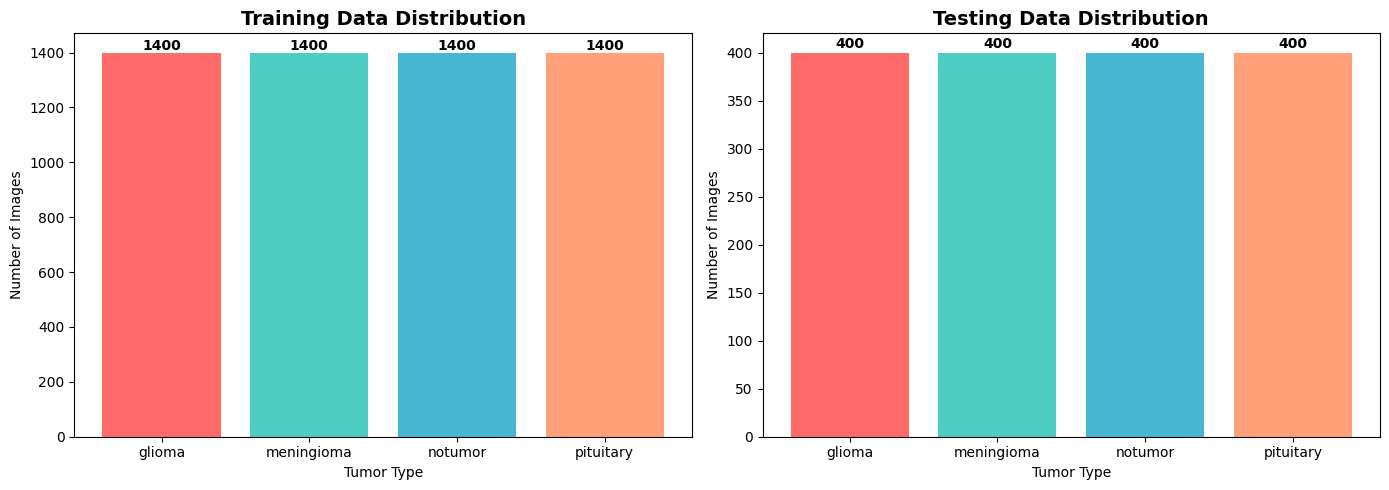

In [3]:
# Data Visualization: Training vs Testing Distribution
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

colors = ['#FF6B6B', '#4ECDC4', '#45B7D1', '#FFA07A']

axes[0].bar(CLASS_NAMES, [train_counts[c] for c in CLASS_NAMES], color=colors)
axes[0].set_title('Training Data Distribution', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Tumor Type')
axes[0].set_ylabel('Number of Images')
for i, v in enumerate([train_counts[c] for c in CLASS_NAMES]):
    axes[0].text(i, v + 10, str(v), ha='center', fontweight='bold')

axes[1].bar(CLASS_NAMES, [test_counts[c] for c in CLASS_NAMES], color=colors)
axes[1].set_title('Testing Data Distribution', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Tumor Type')
axes[1].set_ylabel('Number of Images')
for i, v in enumerate([test_counts[c] for c in CLASS_NAMES]):
    axes[1].text(i, v + 5, str(v), ha='center', fontweight='bold')

plt.tight_layout()
plt.show()

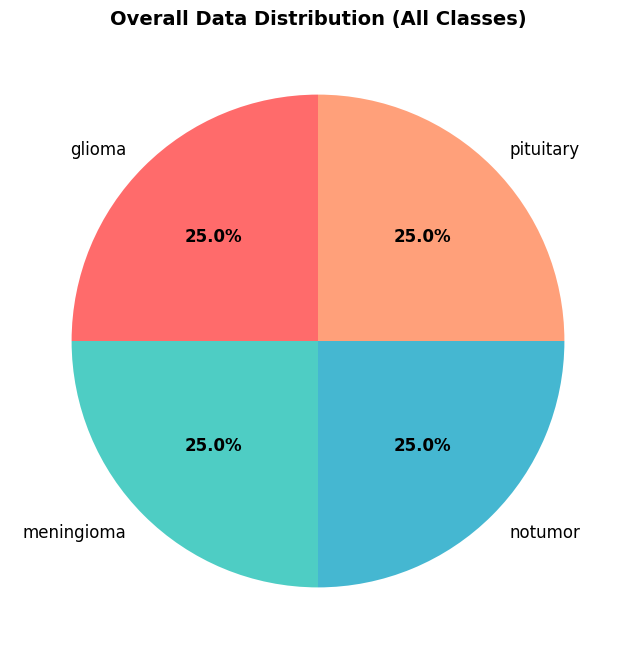

In [4]:
# Pie Chart: Overall Distribution
total_counts = [train_counts[c] + test_counts[c] for c in CLASS_NAMES]
fig, ax = plt.subplots(figsize=(8, 8))
wedges, texts, autotexts = ax.pie(total_counts, labels=CLASS_NAMES, autopct='%1.1f%%', 
                                   colors=colors, startangle=90, textprops={'fontsize': 12})
for autotext in autotexts:
    autotext.set_fontweight('bold')
ax.set_title('Overall Data Distribution (All Classes)', fontsize=14, fontweight='bold')
plt.show()

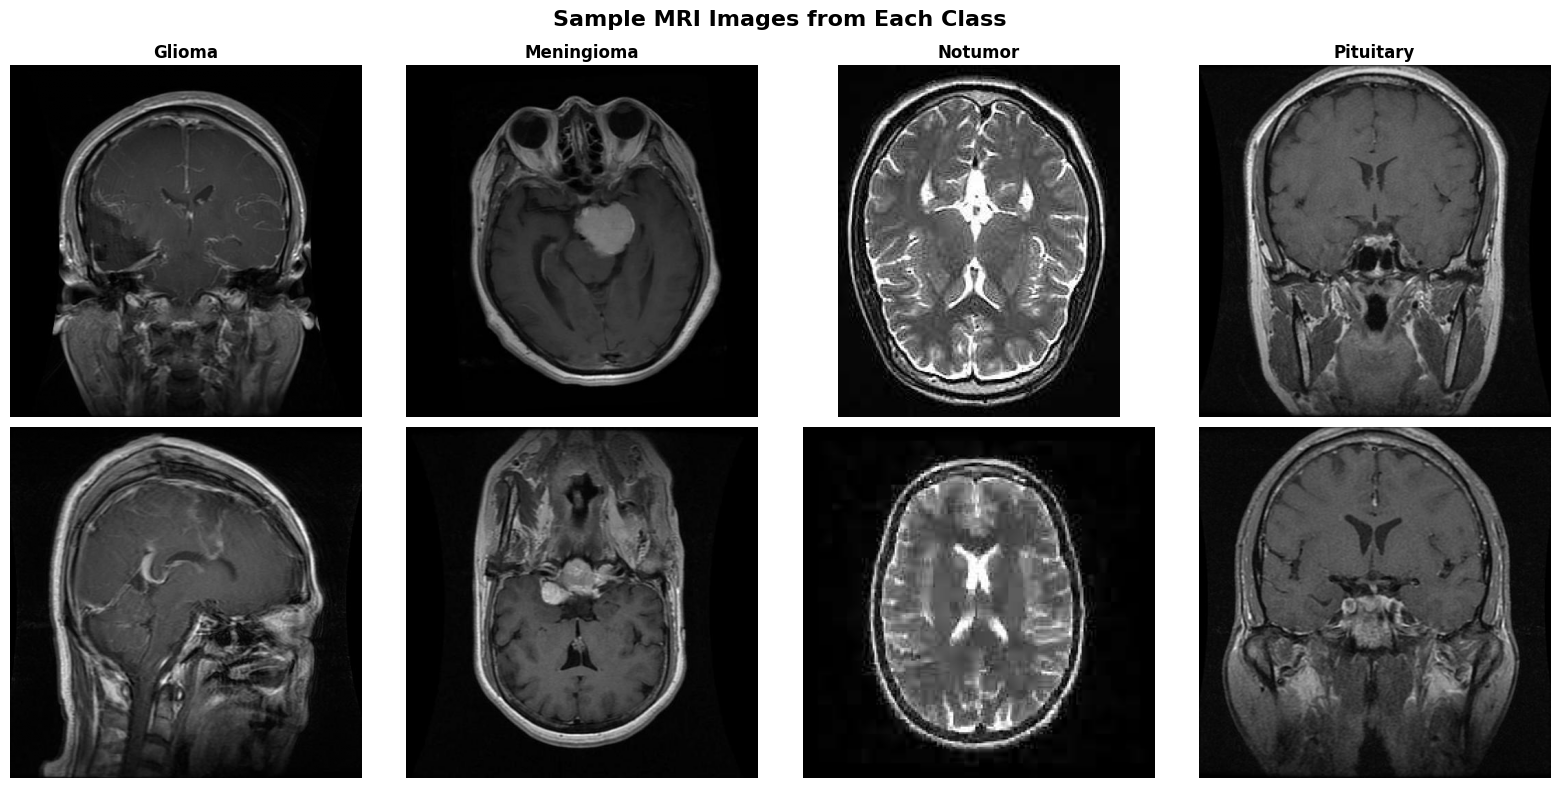

In [5]:
# Display Sample MRI Images from Each Class
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
fig.suptitle('Sample MRI Images from Each Class', fontsize=16, fontweight='bold')

for idx, cls in enumerate(CLASS_NAMES):
    class_dir = os.path.join(TRAIN_DIR, cls)
    images = os.listdir(class_dir)
    
    # Top row - first sample
    img_path = os.path.join(class_dir, images[0])
    img = Image.open(img_path)
    axes[0, idx].imshow(img, cmap='gray')
    axes[0, idx].set_title(cls.capitalize(), fontsize=12, fontweight='bold')
    axes[0, idx].axis('off')
    
    # Bottom row - second sample
    img_path2 = os.path.join(class_dir, images[1])
    img2 = Image.open(img_path2)
    axes[1, idx].imshow(img2, cmap='gray')
    axes[1, idx].axis('off')

plt.tight_layout()
plt.show()

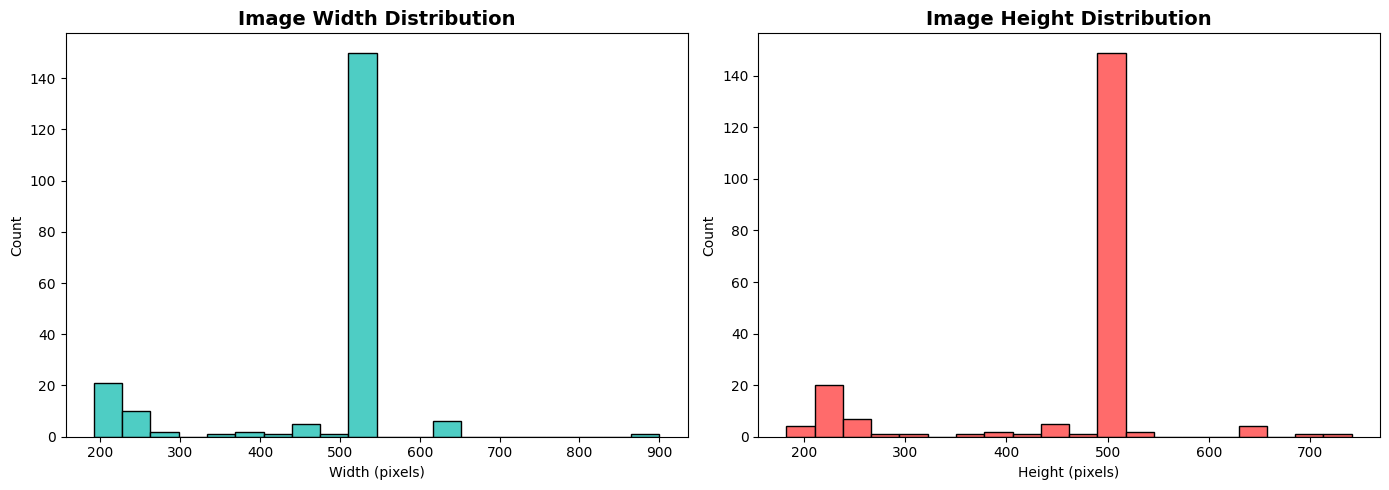

Average Width: 466, Average Height: 466


In [6]:
# Image Size Analysis
widths = []
heights = []
for cls in CLASS_NAMES:
    class_dir = os.path.join(TRAIN_DIR, cls)
    for img_name in os.listdir(class_dir)[:50]:  # Check first 50 images per class
        img_path = os.path.join(class_dir, img_name)
        try:
            img = Image.open(img_path)
            w, h = img.size
            widths.append(w)
            heights.append(h)
        except:
            pass

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].hist(widths, bins=20, color='#4ECDC4', edgecolor='black')
axes[0].set_title('Image Width Distribution', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Width (pixels)')
axes[0].set_ylabel('Count')

axes[1].hist(heights, bins=20, color='#FF6B6B', edgecolor='black')
axes[1].set_title('Image Height Distribution', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Height (pixels)')
axes[1].set_ylabel('Count')

plt.tight_layout()
plt.show()
print(f"Average Width: {np.mean(widths):.0f}, Average Height: {np.mean(heights):.0f}")

## Dataset Preparation

In [7]:
# Dataset Preparation using TensorFlow
train_ds = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR,
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    label_mode='categorical',
    class_names=CLASS_NAMES,
    shuffle=True
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    TEST_DIR,
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    label_mode='categorical',
    class_names=CLASS_NAMES,
    shuffle=False
)

AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.prefetch(buffer_size=AUTOTUNE)
test_ds = test_ds.prefetch(buffer_size=AUTOTUNE)

Found 5600 files belonging to 4 classes.


Found 1600 files belonging to 4 classes.


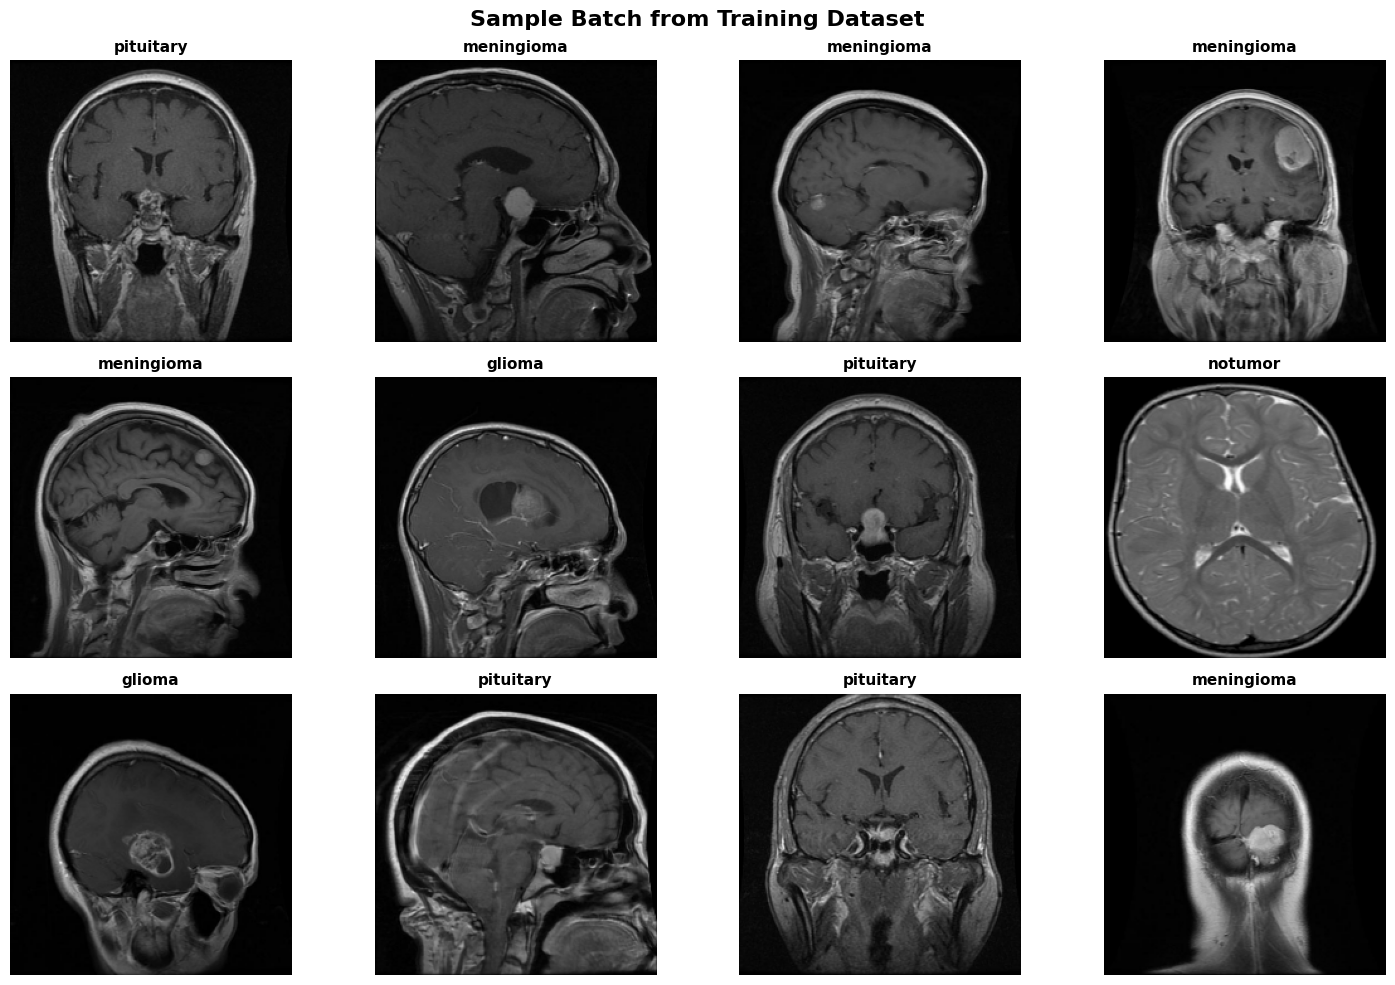

In [8]:
# Visualize a Batch of Training Images
plt.figure(figsize=(15, 10))
for images, labels in train_ds.take(1):
    for i in range(min(12, len(images))):
        ax = plt.subplot(3, 4, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        label_idx = np.argmax(labels[i])
        plt.title(CLASS_NAMES[label_idx], fontsize=11, fontweight='bold')
        plt.axis("off")
plt.suptitle('Sample Batch from Training Dataset', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

## Model Architecture

In [9]:
# Model 1: EfficientNetV2
def create_efficientnet_model():
    base_model = EfficientNetV2S(input_shape=(IMG_SIZE, IMG_SIZE, 3), include_top=False, weights='imagenet')
    base_model.trainable = False
    
    model = models.Sequential([
        base_model,
        layers.GlobalAveragePooling2D(),
        layers.Dropout(0.3),
        layers.Dense(512, activation='relu'),
        layers.BatchNormalization(),
        layers.Dropout(0.2),
        layers.Dense(NUM_CLASSES, activation='softmax')
    ])
    model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
    return model

# Model 2: InceptionV3
def create_inception_model():
    base_model = InceptionV3(input_shape=(IMG_SIZE, IMG_SIZE, 3), include_top=False, weights='imagenet')
    base_model.trainable = False
    
    model = models.Sequential([
        layers.Rescaling(1./127.5, offset=-1, input_shape=(IMG_SIZE, IMG_SIZE, 3)),
        base_model,
        layers.GlobalAveragePooling2D(),
        layers.Dropout(0.3),
        layers.Dense(512, activation='relu'),
        layers.BatchNormalization(),
        layers.Dropout(0.2),
        layers.Dense(NUM_CLASSES, activation='softmax')
    ])
    model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
    return model

print("Model architectures defined successfully!")

Model architectures defined successfully!


## Model Training

In [10]:
# Train EfficientNetV2
print("--- Training EfficientNetV2 ---")
eff_model = create_efficientnet_model()
eff_history = eff_model.fit(train_ds, validation_data=test_ds, epochs=NUM_EPOCHS)
eff_model.save(os.path.join(MODELS_DIR, 'efficientnet_v2.h5'))
print("EfficientNetV2 model saved to models/efficientnet_v2.h5")

--- Training EfficientNetV2 ---


  1/175 ━━━━━━━━━━━━━━━━━━━━ 45:38 16s/step - accuracy: 0.3750 - loss: 2.0068

  2/175 ━━━━━━━━━━━━━━━━━━━━ 5:21 2s/step - accuracy: 0.3750 - loss: 1.9981  

  3/175 ━━━━━━━━━━━━━━━━━━━━ 5:20 2s/step - accuracy: 0.3750 - loss: 1.9678

  4/175 ━━━━━━━━━━━━━━━━━━━━ 5:14 2s/step - accuracy: 0.3906 - loss: 1.9221

  5/175 ━━━━━━━━━━━━━━━━━━━━ 5:24 2s/step - accuracy: 0.4062 - loss: 1.8844

... (168 outputs left out)

174/175 ━━━━━━━━━━━━━━━━━━━━ 1s 2s/step - accuracy: 0.7513 - loss: 0.8043

175/175 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.7516 - loss: 0.8032

175/175 ━━━━━━━━━━━━━━━━━━━━ 485s 3s/step - accuracy: 0.8027 - loss: 0.6055 - val_accuracy: 0.8506 - val_loss: 0.4241


EfficientNetV2 model saved to models/efficientnet_v2.h5


In [11]:
# Train InceptionV3
print("--- Training InceptionV3 ---")
inception_model = create_inception_model()
inc_history = inception_model.fit(train_ds, validation_data=test_ds, epochs=NUM_EPOCHS)
inception_model.save(os.path.join(MODELS_DIR, 'inception_v3.h5'))
print("InceptionV3 model saved to models/inception_v3.h5")

--- Training InceptionV3 ---


  1/175 ━━━━━━━━━━━━━━━━━━━━ 2:13:16 46s/step - accuracy: 0.1875 - loss: 2.3234

  2/175 ━━━━━━━━━━━━━━━━━━━━ 2:22 822ms/step - accuracy: 0.2500 - loss: 2.1802 

  3/175 ━━━━━━━━━━━━━━━━━━━━ 2:17 798ms/step - accuracy: 0.2917 - loss: 2.0611

  4/175 ━━━━━━━━━━━━━━━━━━━━ 2:14 788ms/step - accuracy: 0.3262 - loss: 1.9681

  5/175 ━━━━━━━━━━━━━━━━━━━━ 2:13 785ms/step - accuracy: 0.3497 - loss: 1.9017

... (168 outputs left out)

174/175 ━━━━━━━━━━━━━━━━━━━━ 0s 805ms/step - accuracy: 0.7232 - loss: 0.8346

175/175 ━━━━━━━━━━━━━━━━━━━━ 0s 805ms/step - accuracy: 0.7236 - loss: 0.8334

175/175 ━━━━━━━━━━━━━━━━━━━━ 233s 1s/step - accuracy: 0.7907 - loss: 0.6229 - val_accuracy: 0.8475 - val_loss: 0.4411


InceptionV3 model saved to models/inception_v3.h5


## Training & Validation Accuracy / Loss Graphs (Per Model)
Below we visualize the **training accuracy vs validation accuracy** and **training loss vs validation loss** for each model across all epochs.

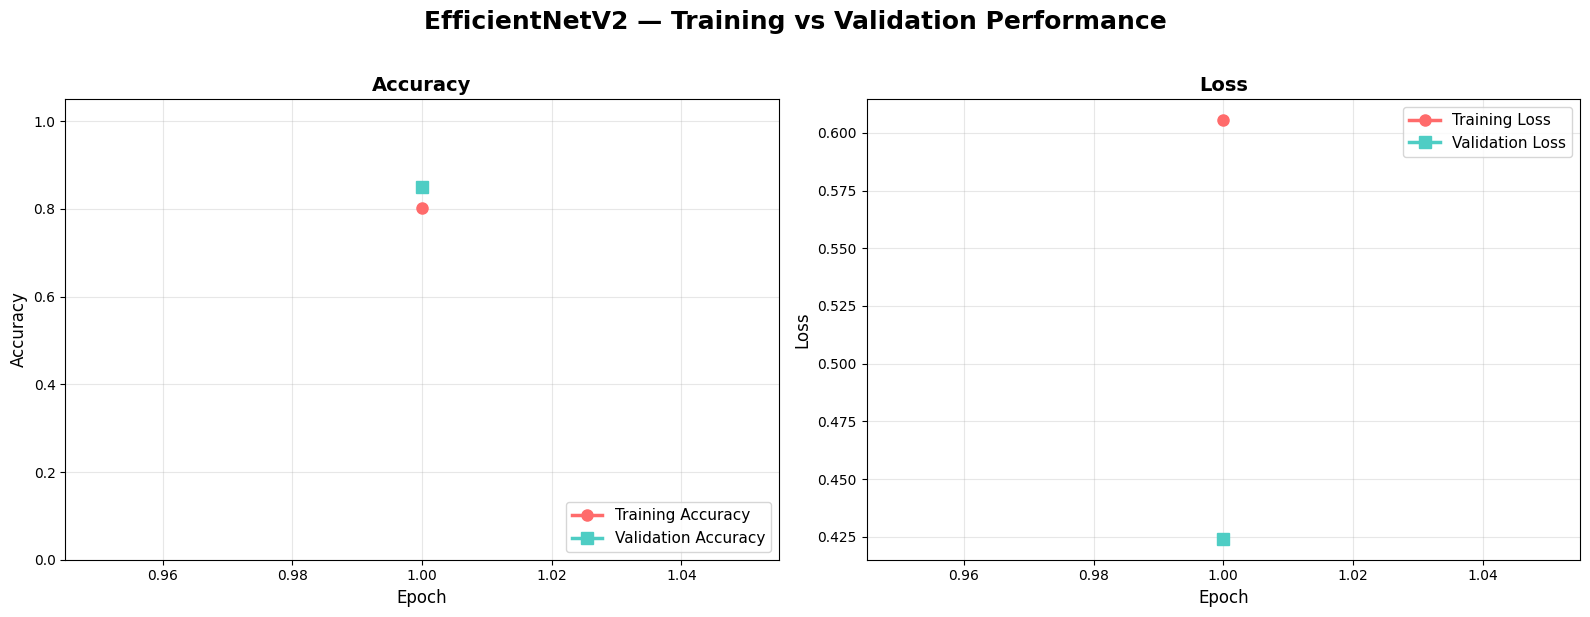

EfficientNetV2 — Final Training Accuracy: 80.27%
EfficientNetV2 — Final Validation Accuracy: 85.06%


In [12]:
# ========== EfficientNetV2: Training vs Validation Accuracy & Loss ==========

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle('EfficientNetV2 — Training vs Validation Performance', fontsize=18, fontweight='bold', y=1.02)

epochs_range = range(1, len(eff_history.history['accuracy']) + 1)

# Accuracy subplot
axes[0].plot(epochs_range, eff_history.history['accuracy'], 'o-', color='#FF6B6B', linewidth=2.5, markersize=8, label='Training Accuracy')
axes[0].plot(epochs_range, eff_history.history['val_accuracy'], 's-', color='#4ECDC4', linewidth=2.5, markersize=8, label='Validation Accuracy')
axes[0].set_title('Accuracy', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Epoch', fontsize=12)
axes[0].set_ylabel('Accuracy', fontsize=12)
axes[0].legend(fontsize=11, loc='lower right')
axes[0].grid(True, alpha=0.3)
axes[0].set_ylim([0, 1.05])

# Loss subplot
axes[1].plot(epochs_range, eff_history.history['loss'], 'o-', color='#FF6B6B', linewidth=2.5, markersize=8, label='Training Loss')
axes[1].plot(epochs_range, eff_history.history['val_loss'], 's-', color='#4ECDC4', linewidth=2.5, markersize=8, label='Validation Loss')
axes[1].set_title('Loss', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Epoch', fontsize=12)
axes[1].set_ylabel('Loss', fontsize=12)
axes[1].legend(fontsize=11, loc='upper right')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print(f"EfficientNetV2 — Final Training Accuracy: {eff_history.history['accuracy'][-1]*100:.2f}%")
print(f"EfficientNetV2 — Final Validation Accuracy: {eff_history.history['val_accuracy'][-1]*100:.2f}%")


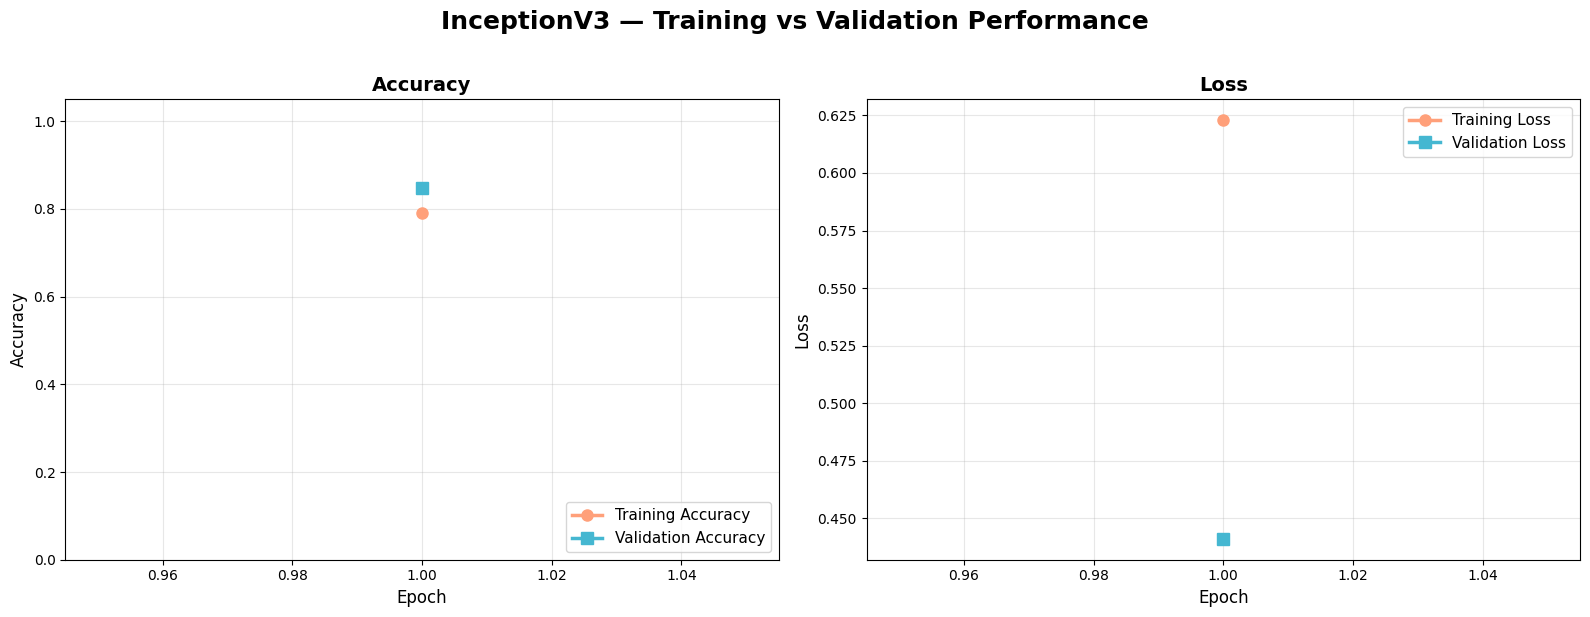

InceptionV3 — Final Training Accuracy: 79.07%
InceptionV3 — Final Validation Accuracy: 84.75%


In [13]:
# ========== InceptionV3: Training vs Validation Accuracy & Loss ==========

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle('InceptionV3 — Training vs Validation Performance', fontsize=18, fontweight='bold', y=1.02)

epochs_range_inc = range(1, len(inc_history.history['accuracy']) + 1)

# Accuracy subplot
axes[0].plot(epochs_range_inc, inc_history.history['accuracy'], 'o-', color='#FFA07A', linewidth=2.5, markersize=8, label='Training Accuracy')
axes[0].plot(epochs_range_inc, inc_history.history['val_accuracy'], 's-', color='#45B7D1', linewidth=2.5, markersize=8, label='Validation Accuracy')
axes[0].set_title('Accuracy', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Epoch', fontsize=12)
axes[0].set_ylabel('Accuracy', fontsize=12)
axes[0].legend(fontsize=11, loc='lower right')
axes[0].grid(True, alpha=0.3)
axes[0].set_ylim([0, 1.05])

# Loss subplot
axes[1].plot(epochs_range_inc, inc_history.history['loss'], 'o-', color='#FFA07A', linewidth=2.5, markersize=8, label='Training Loss')
axes[1].plot(epochs_range_inc, inc_history.history['val_loss'], 's-', color='#45B7D1', linewidth=2.5, markersize=8, label='Validation Loss')
axes[1].set_title('Loss', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Epoch', fontsize=12)
axes[1].set_ylabel('Loss', fontsize=12)
axes[1].legend(fontsize=11, loc='upper right')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print(f"InceptionV3 — Final Training Accuracy: {inc_history.history['accuracy'][-1]*100:.2f}%")
print(f"InceptionV3 — Final Validation Accuracy: {inc_history.history['val_accuracy'][-1]*100:.2f}%")


## EfficientNetV2 vs InceptionV3 — Accuracy Comparison
Below we compare both models' **training accuracy** and **validation (testing) accuracy** side by side to see which model performs better.

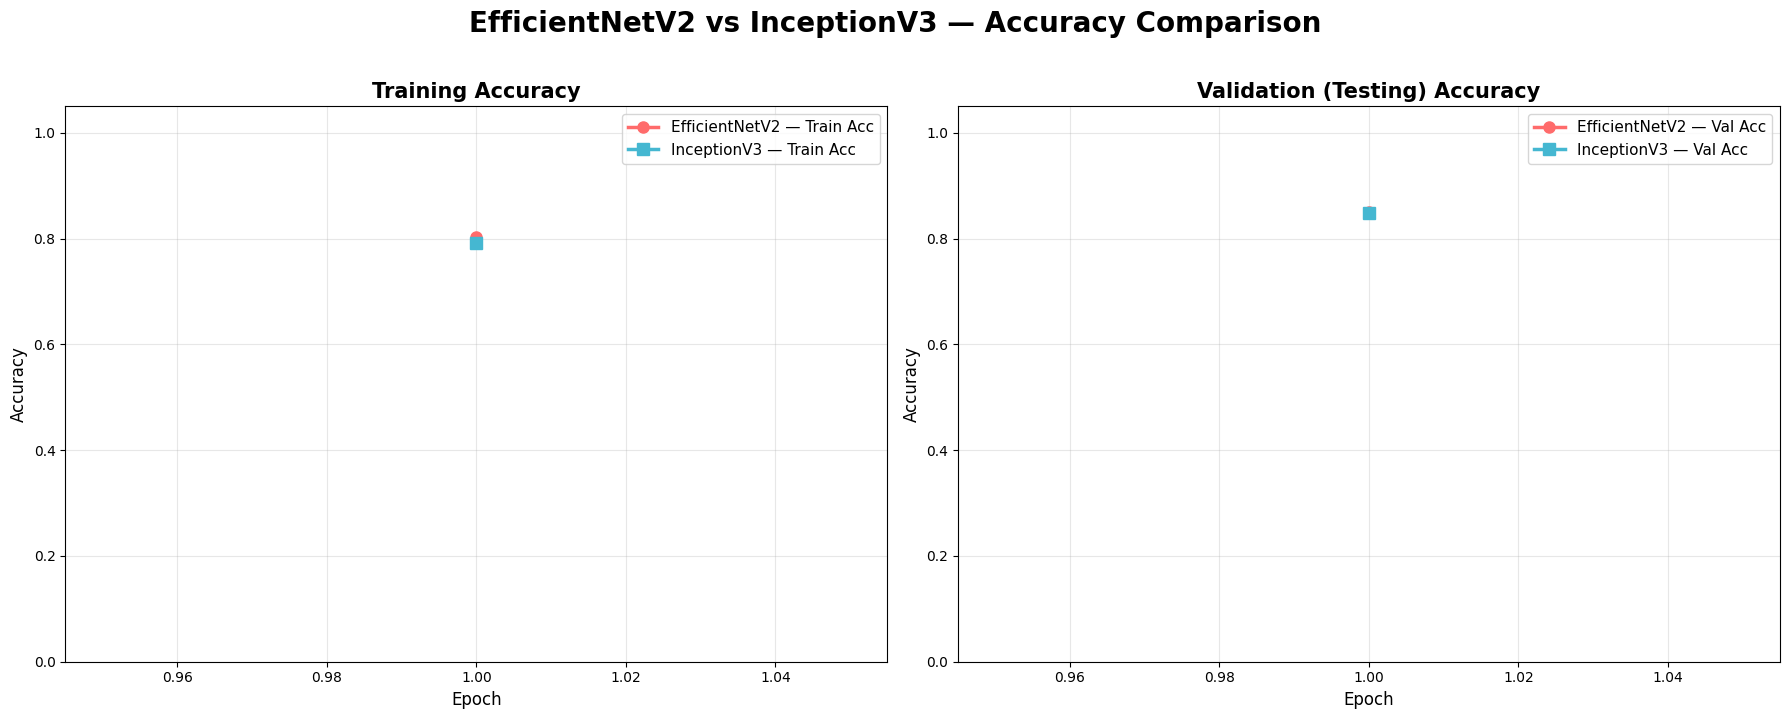

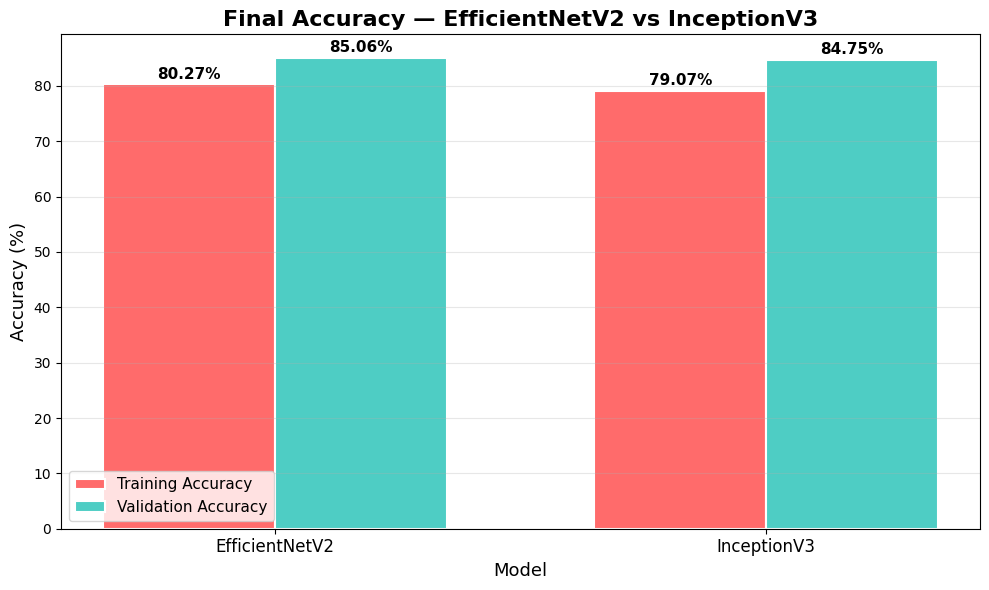


  MODEL ACCURACY COMPARISON SUMMARY
  EfficientNetV2 — Training Accuracy:   80.27%
  EfficientNetV2 — Validation Accuracy:  85.06%
  InceptionV3    — Training Accuracy:   79.07%
  InceptionV3    — Validation Accuracy:  84.75%
  ✅ EfficientNetV2 has HIGHER validation accuracy by 0.31%


In [14]:
# ========== EfficientNetV2 vs InceptionV3: Combined Accuracy Comparison ==========

fig, axes = plt.subplots(1, 2, figsize=(18, 7))
fig.suptitle('EfficientNetV2 vs InceptionV3 — Accuracy Comparison', fontsize=20, fontweight='bold', y=1.02)

# Determine the max epochs between both models
eff_epochs = range(1, len(eff_history.history['accuracy']) + 1)
inc_epochs = range(1, len(inc_history.history['accuracy']) + 1)

# ---- Subplot 1: Training Accuracy Comparison ----
axes[0].plot(eff_epochs, eff_history.history['accuracy'], 'o-', color='#FF6B6B', linewidth=2.5, markersize=8, label='EfficientNetV2 — Train Acc')
axes[0].plot(inc_epochs, inc_history.history['accuracy'], 's-', color='#45B7D1', linewidth=2.5, markersize=8, label='InceptionV3 — Train Acc')
axes[0].set_title('Training Accuracy', fontsize=15, fontweight='bold')
axes[0].set_xlabel('Epoch', fontsize=12)
axes[0].set_ylabel('Accuracy', fontsize=12)
axes[0].legend(fontsize=11)
axes[0].grid(True, alpha=0.3)
axes[0].set_ylim([0, 1.05])

# ---- Subplot 2: Validation (Testing) Accuracy Comparison ----
axes[1].plot(eff_epochs, eff_history.history['val_accuracy'], 'o-', color='#FF6B6B', linewidth=2.5, markersize=8, label='EfficientNetV2 — Val Acc')
axes[1].plot(inc_epochs, inc_history.history['val_accuracy'], 's-', color='#45B7D1', linewidth=2.5, markersize=8, label='InceptionV3 — Val Acc')
axes[1].set_title('Validation (Testing) Accuracy', fontsize=15, fontweight='bold')
axes[1].set_xlabel('Epoch', fontsize=12)
axes[1].set_ylabel('Accuracy', fontsize=12)
axes[1].legend(fontsize=11)
axes[1].grid(True, alpha=0.3)
axes[1].set_ylim([0, 1.05])

plt.tight_layout()
plt.show()

# ---- Summary Bar Chart: Final Accuracy Comparison ----
fig, ax = plt.subplots(figsize=(10, 6))

models_list = ['EfficientNetV2', 'InceptionV3']
train_accs = [eff_history.history['accuracy'][-1] * 100, inc_history.history['accuracy'][-1] * 100]
val_accs = [eff_history.history['val_accuracy'][-1] * 100, inc_history.history['val_accuracy'][-1] * 100]

x = np.arange(len(models_list))
width = 0.35

bars1 = ax.bar(x - width/2, train_accs, width, label='Training Accuracy', color='#FF6B6B', edgecolor='white', linewidth=1.5)
bars2 = ax.bar(x + width/2, val_accs, width, label='Validation Accuracy', color='#4ECDC4', edgecolor='white', linewidth=1.5)

ax.set_title('Final Accuracy — EfficientNetV2 vs InceptionV3', fontsize=16, fontweight='bold')
ax.set_xlabel('Model', fontsize=13)
ax.set_ylabel('Accuracy (%)', fontsize=13)
ax.set_xticks(x)
ax.set_xticklabels(models_list, fontsize=12)
ax.legend(fontsize=11)
ax.grid(axis='y', alpha=0.3)

# Add value labels on bars
for bar in bars1:
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2., height + 0.5, f'{height:.2f}%', ha='center', va='bottom', fontweight='bold', fontsize=11)

for bar in bars2:
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2., height + 0.5, f'{height:.2f}%', ha='center', va='bottom', fontweight='bold', fontsize=11)

plt.tight_layout()
plt.show()

# Print summary
print('\n' + '='*60)
print('  MODEL ACCURACY COMPARISON SUMMARY')
print('='*60)
print(f'  EfficientNetV2 — Training Accuracy:   {train_accs[0]:.2f}%')
print(f'  EfficientNetV2 — Validation Accuracy:  {val_accs[0]:.2f}%')
print(f'  InceptionV3    — Training Accuracy:   {train_accs[1]:.2f}%')
print(f'  InceptionV3    — Validation Accuracy:  {val_accs[1]:.2f}%')
print('='*60)

if val_accs[0] > val_accs[1]:
    print(f'  ✅ EfficientNetV2 has HIGHER validation accuracy by {val_accs[0]-val_accs[1]:.2f}%')
elif val_accs[1] > val_accs[0]:
    print(f'  ✅ InceptionV3 has HIGHER validation accuracy by {val_accs[1]-val_accs[0]:.2f}%')
else:
    print(f'  ✅ Both models have EQUAL validation accuracy!')
print('='*60)


## Model Evaluation & Comparison

         Model Validation Accuracy Validation Loss
EfficientNetV2              85.06%          0.4241
   InceptionV3              84.75%          0.4411


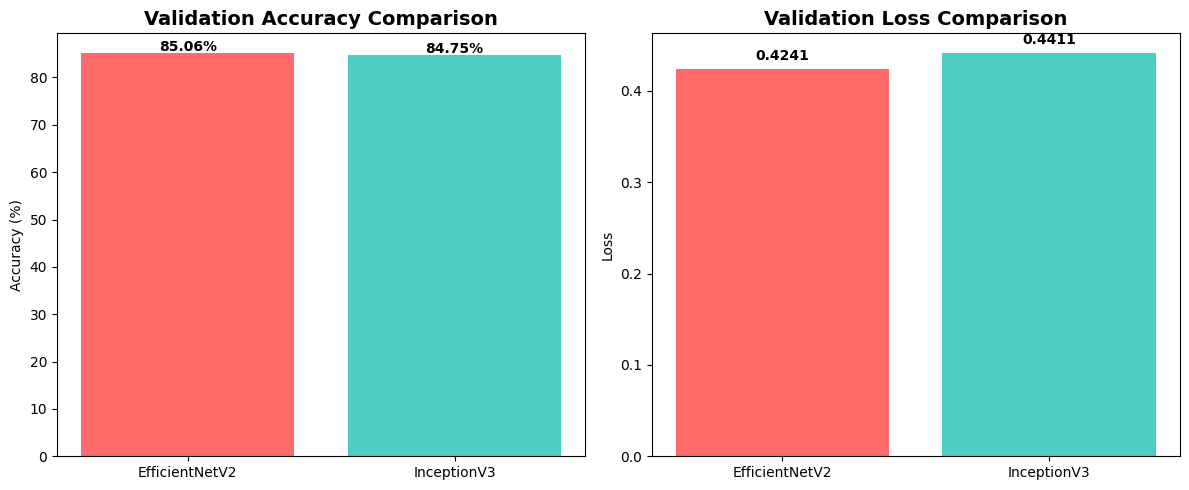

In [15]:
# Model Comparison
eff_acc = eff_history.history['val_accuracy'][-1]
inc_acc = inc_history.history['val_accuracy'][-1]
eff_loss = eff_history.history['val_loss'][-1]
inc_loss = inc_history.history['val_loss'][-1]

comparison_df = pd.DataFrame({
    'Model': ['EfficientNetV2', 'InceptionV3'],
    'Validation Accuracy': [f"{eff_acc*100:.2f}%", f"{inc_acc*100:.2f}%"],
    'Validation Loss': [f"{eff_loss:.4f}", f"{inc_loss:.4f}"]
})
print(comparison_df.to_string(index=False))

# Bar chart comparison
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
model_names = ['EfficientNetV2', 'InceptionV3']
accuracies = [eff_acc * 100, inc_acc * 100]
losses = [eff_loss, inc_loss]

axes[0].bar(model_names, accuracies, color=['#FF6B6B', '#4ECDC4'])
axes[0].set_title('Validation Accuracy Comparison', fontsize=14, fontweight='bold')
axes[0].set_ylabel('Accuracy (%)')
for i, v in enumerate(accuracies):
    axes[0].text(i, v + 0.5, f"{v:.2f}%", ha='center', fontweight='bold')

axes[1].bar(model_names, losses, color=['#FF6B6B', '#4ECDC4'])
axes[1].set_title('Validation Loss Comparison', fontsize=14, fontweight='bold')
axes[1].set_ylabel('Loss')
for i, v in enumerate(losses):
    axes[1].text(i, v + 0.01, f"{v:.4f}", ha='center', fontweight='bold')

plt.tight_layout()
plt.show()

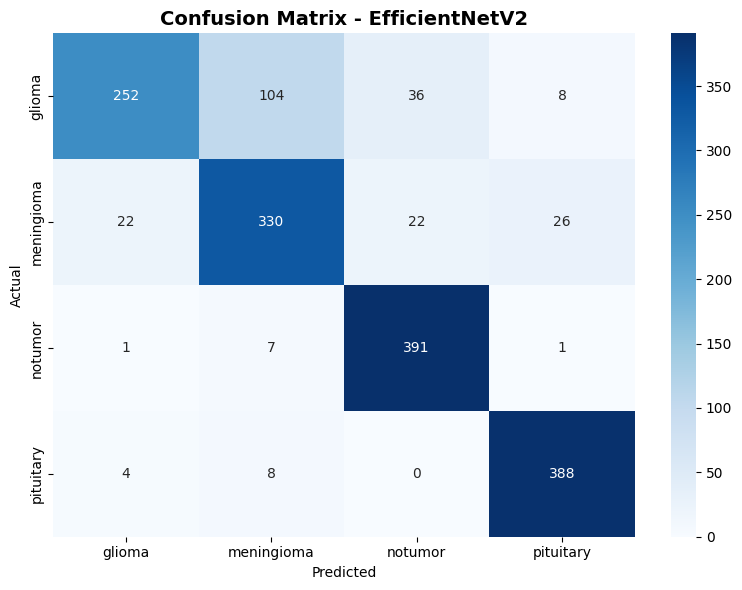


Classification Report - EfficientNetV2:
              precision    recall  f1-score   support

      glioma       0.90      0.63      0.74       400
  meningioma       0.73      0.82      0.78       400
     notumor       0.87      0.98      0.92       400
   pituitary       0.92      0.97      0.94       400

    accuracy                           0.85      1600
   macro avg       0.86      0.85      0.85      1600
weighted avg       0.86      0.85      0.85      1600



In [16]:
# Predictions and Confusion Matrix for EfficientNetV2
all_preds = []
all_labels = []
for images, labels in test_ds:
    preds = eff_model.predict(images, verbose=0)
    all_preds.extend(np.argmax(preds, axis=1))
    all_labels.extend(np.argmax(labels.numpy(), axis=1))

cm = confusion_matrix(all_labels, all_preds)
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=ax)
ax.set_title('Confusion Matrix - EfficientNetV2', fontsize=14, fontweight='bold')
ax.set_xlabel('Predicted')
ax.set_ylabel('Actual')
plt.tight_layout()
plt.show()

print("\nClassification Report - EfficientNetV2:")
print(classification_report(all_labels, all_preds, target_names=CLASS_NAMES))

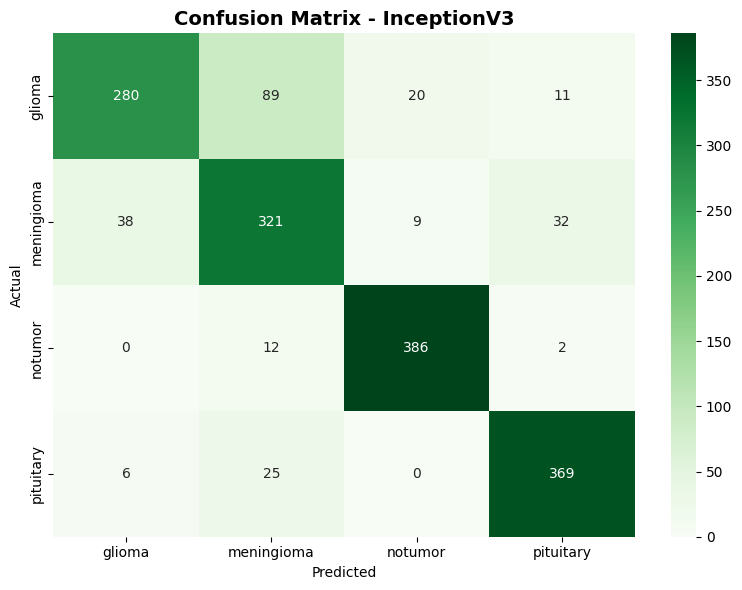


Classification Report - InceptionV3:
              precision    recall  f1-score   support

      glioma       0.86      0.70      0.77       400
  meningioma       0.72      0.80      0.76       400
     notumor       0.93      0.96      0.95       400
   pituitary       0.89      0.92      0.91       400

    accuracy                           0.85      1600
   macro avg       0.85      0.85      0.85      1600
weighted avg       0.85      0.85      0.85      1600



In [17]:
# Predictions and Confusion Matrix for InceptionV3
all_preds_inc = []
all_labels_inc = []
for images, labels in test_ds:
    preds = inception_model.predict(images, verbose=0)
    all_preds_inc.extend(np.argmax(preds, axis=1))
    all_labels_inc.extend(np.argmax(labels.numpy(), axis=1))

cm_inc = confusion_matrix(all_labels_inc, all_preds_inc)
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(cm_inc, annot=True, fmt='d', cmap='Greens', xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=ax)
ax.set_title('Confusion Matrix - InceptionV3', fontsize=14, fontweight='bold')
ax.set_xlabel('Predicted')
ax.set_ylabel('Actual')
plt.tight_layout()
plt.show()

print("\nClassification Report - InceptionV3:")
print(classification_report(all_labels_inc, all_preds_inc, target_names=CLASS_NAMES))

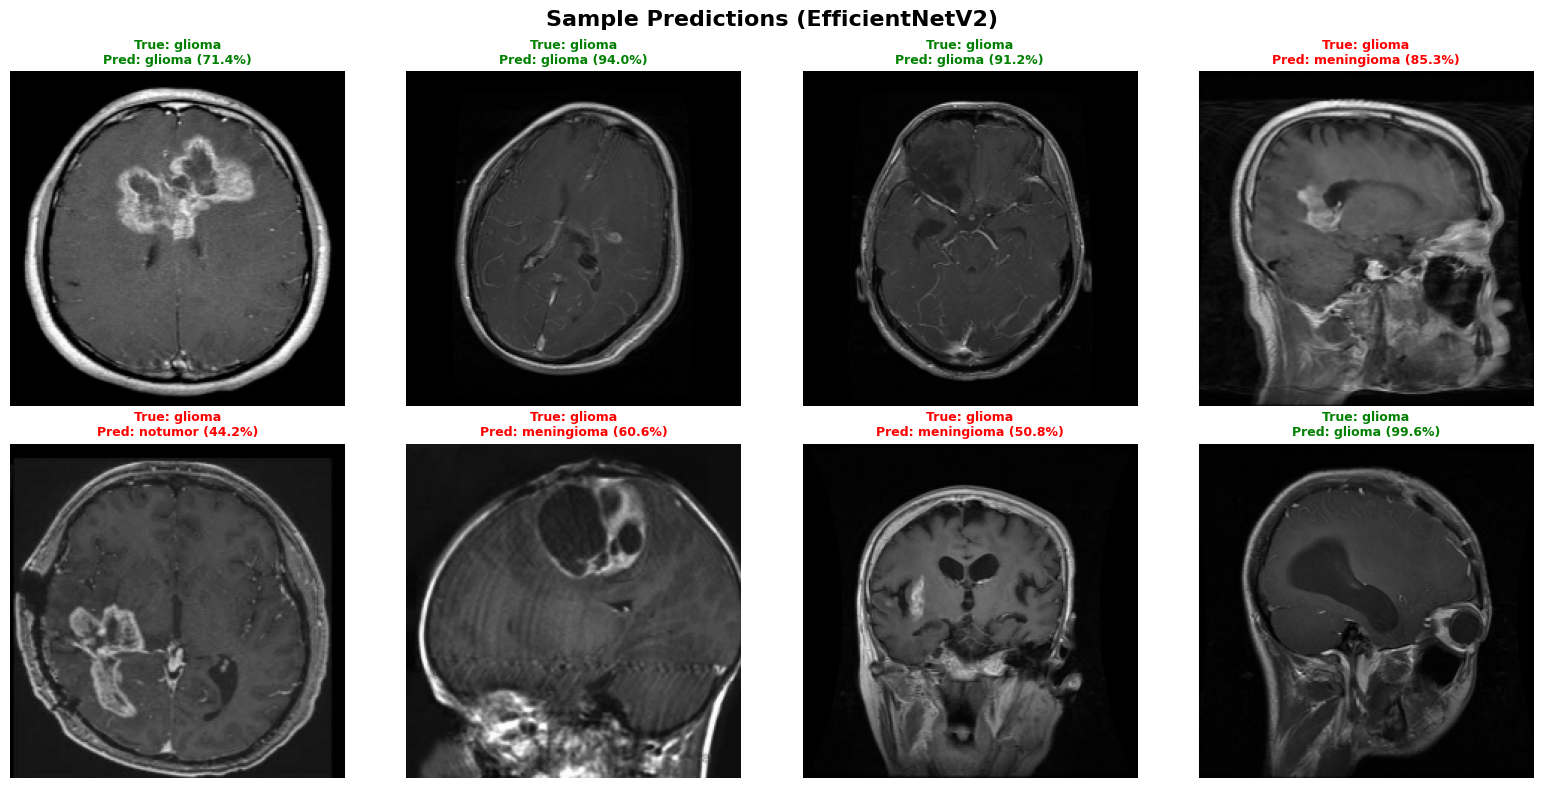

In [18]:
# Sample Predictions with Images
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
fig.suptitle('Sample Predictions (EfficientNetV2)', fontsize=16, fontweight='bold')

for images, labels in test_ds.take(1):
    preds = eff_model.predict(images, verbose=0)
    for i in range(min(8, len(images))):
        row = i // 4
        col = i % 4
        axes[row, col].imshow(images[i].numpy().astype("uint8"))
        true_label = CLASS_NAMES[np.argmax(labels[i])]
        pred_label = CLASS_NAMES[np.argmax(preds[i])]
        confidence = np.max(preds[i]) * 100
        color = 'green' if true_label == pred_label else 'red'
        axes[row, col].set_title(f"True: {true_label}\nPred: {pred_label} ({confidence:.1f}%)", 
                                  fontsize=9, color=color, fontweight='bold')
        axes[row, col].axis('off')

plt.tight_layout()
plt.show()